In [12]:
import matplotlib.pyplot as plt
from pycalphad import Database, binplot, equilibrium
import pycalphad.variables as v

## Plot the phase diagram from database

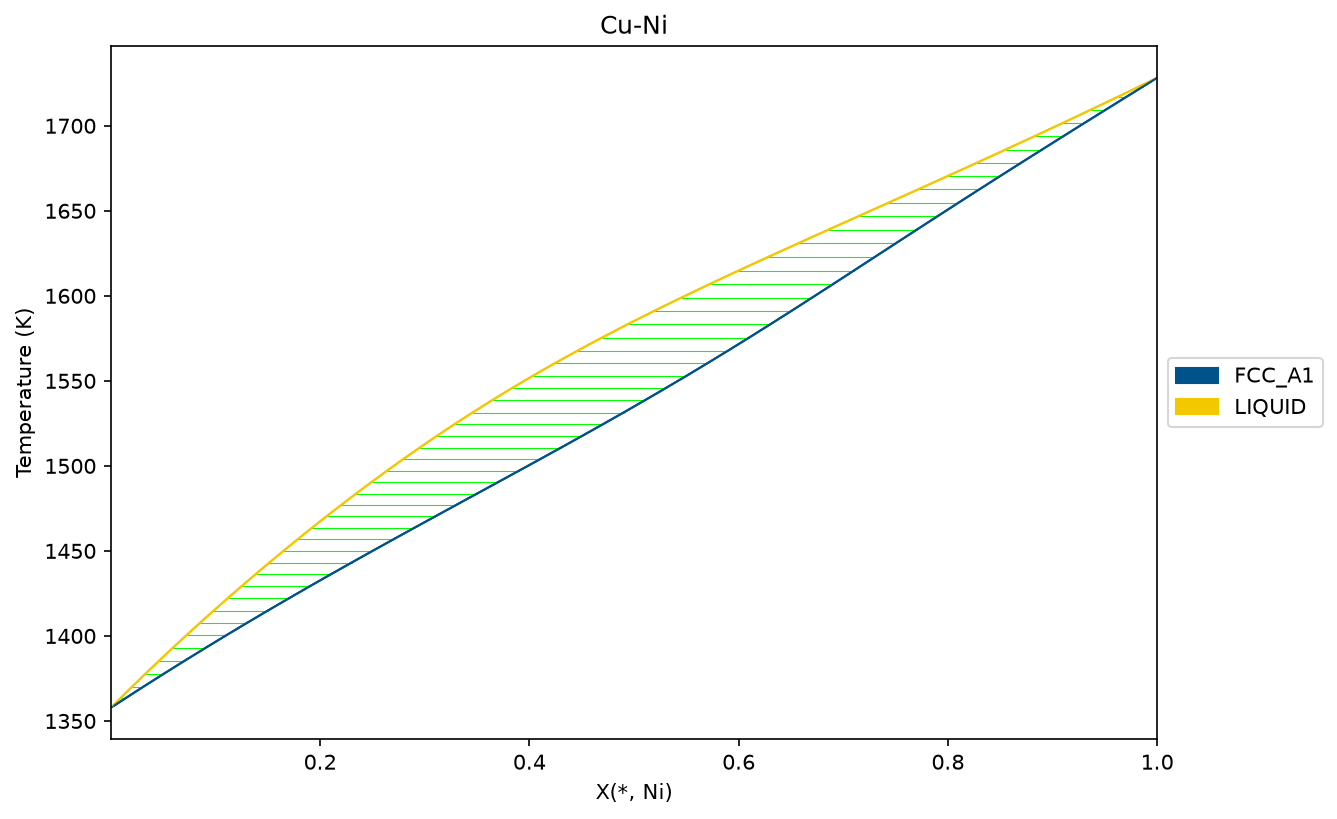

In [42]:
# Load database
dbf = Database('calphad_server/cuni_cost507.tdb')
# Set the components to consider, including vacanies (VA) explictly.
comps = ['CU', 'NI', 'VA']
# Get all the phases in the database programatically
phases = list(dbf.phases.keys())
# Create the dictionary of conditions
conditions = {
    v.N: 1, v.P: 101325,
    v.T: (1000, 1900, 10),  # (start, stop, step)
    v.X('NI'): (1e-5, 1, 0.02),   # (start, stop, step)
}

# Create a matplotlib Figure object and get the active Axes
fig = plt.figure(figsize=(9,6), dpi=150)
axes = fig.gca()

# Plot by passing in all the variables
binplot(dbf, comps, phases, conditions, plot_kwargs=dict(ax=axes))

plt.show()

In [32]:
#calculate equilibrium at a specific T, P, and overall composition
eq_result = equilibrium(db, comps, phases, {v.T: 1730, v.P: 101325, v.X('AL'): 0.1})
print(eq_result)

<xarray.Dataset> Size: 420B
Dimensions:    (N: 1, P: 1, T: 1, X_AL: 1, vertex: 3, component: 2,
                internal_dof: 7)
Coordinates:
  * N          (N) float64 8B 1.0
  * P          (P) float64 8B 1.013e+05
  * T          (T) float64 8B 1.73e+03
  * X_AL       (X_AL) float64 8B 0.1
  * vertex     (vertex) int64 24B 0 1 2
  * component  (component) <U2 16B 'AL' 'NI'
Dimensions without coordinates: internal_dof
Data variables:
    NP         (N, P, T, X_AL, vertex) float64 24B 1.0 nan nan
    GM         (N, P, T, X_AL) float64 8B -1.164e+05
    MU         (N, P, T, X_AL, component) float64 16B -2.396e+05 -1.027e+05
    X          (N, P, T, X_AL, vertex, component) float64 48B 0.1 0.9 ... nan
    Y          (N, P, T, X_AL, vertex, internal_dof) float64 168B 0.1 ... nan
    Phase      (N, P, T, X_AL, vertex) <U7 84B 'LIQUID' '' ''
Attributes:
    engine:   pycalphad 0.11.2
    created:  2026-11-06T12:43:23.623285


In [37]:
print(eq_result.Phase)

<xarray.DataArray 'Phase' (N: 1, P: 1, T: 1, X_AL: 1, vertex: 3)> Size: 84B
array([[[[['LIQUID', '', '']]]]], dtype='<U7')
Coordinates:
  * N        (N) float64 8B 1.0
  * P        (P) float64 8B 1.013e+05
  * T        (T) float64 8B 1.73e+03
  * X_AL     (X_AL) float64 8B 0.1
  * vertex   (vertex) int64 24B 0 1 2


## Computing properties - phase fractions and phase compositions vs temperature
#### take a single alloy composition and look at how the equilibrium phase fractions and compositions evolve with temperature.